In [1]:
#imports
import numpy as np
from scipy.spatial.distance import cdist
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, minimum_spanning_tree, shortest_path
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from itertools import combinations
import networkx as nx
from pyproj import Geod
from scipy.optimize import differential_evolution
import rasterio
import time

# Helper Functions

## DEM Helpers

In [2]:
def load_dem(dem_file_path = 'C:\\Users\\UserAdmin\\Documents\\GallenIntern\\Anjali\\output_hh.tif'):
  """
  Returns dem_dataset
  """
  try:
    dem_dataset = rasterio.open(dem_file_path)
    print(f"Successfully loaded DEM file: {dem_file_path}")
    print(f"DEM CRS: {dem_dataset.crs}")
    print(f"DEM bounds: {dem_dataset.bounds}")
    print(f"DEM resolution: {dem_dataset.res}")
  except rasterio.errors.RasterioIOError as e:
    print(f"Error loading DEM file: {e}")
    print("Please ensure the DEM file exists at the specified path and is a valid GeoTIFF.")
    dem_dataset = None  # Set to None if loading fails
  return dem_dataset

In [3]:
def get_elevation_at_lonlat(lon, lat, dem_dataset):
    """
    Returns:
        float elevation in metres, or None if the point falls outside the
        DEM's coverage or on a nodata pixel (i.e. we can't determine it).
    """
    try:
        row, col = dem_dataset.index(lon, lat)  # rasterio expects (x, y) = (lon, lat)
        if row < 0 or col < 0 or row >= dem_dataset.height or col >= dem_dataset.width:
            return None
        window = rasterio.windows.Window(col, row, 1, 1)
        value = dem_dataset.read(1, window=window)[0, 0]
        if dem_dataset.nodata is not None and value == dem_dataset.nodata:
            return None
        return float(value)
    except (IndexError, ValueError):
        return None

In [4]:
def is_on_land(lon, lat, dem_dataset, sea_level_threshold=0.0):
    """
    Returns True if the point is on land, False otherwise.
    """
    elevation = get_elevation_at_lonlat(lon, lat, dem_dataset)
    if elevation is None:
        return True #treat unknown as land
    return elevation > sea_level_threshold

In [5]:
def get_elevation_profile(lat1, lon1, lat2, lon2, dem_dataset, num_points=50):
    """
    Fetches elevation profile between two LLA points
    Returns: A list of dictionaries, each containing 'elevation' and 'location' (lat, lng).
    """
    elevations_data = []
    # Generate intermediate points along the path
    lats = np.linspace(lat1, lat2, num_points)
    lons = np.linspace(lon1, lon2, num_points)

    for i in range(num_points):
        current_lat = lats[i]
        current_lon = lons[i]

        # Query elevation from the DEM dataset
        try:
            # Read elevation values at lat,lon
            # This requires a transform to convert lat/lon to pixel coordinates and then reading the pixel value.
            row, col = dem_dataset.index(current_lon, current_lat) # rasterio expects (x, y) = (lon, lat)
            elevation = dem_dataset.read(1)[row, col]
            elevations_data.append({'elevation': float(elevation), 'location': {'lat': current_lat, 'lng': current_lon}})
        except Exception as e:
            # Handle cases where the point is outside the DEM coverage or other errors
            print(f"Warning: Could not get elevation for ({current_lat:.4f}, {current_lon:.4f}): {e}")
            elevations_data.append({'elevation': 0.0, 'location': {'lat': current_lat, 'lng': current_lon}}) # Default to 0m if error
    return elevations_data

## Input

In [6]:
def generate_convoy_lla(dem_dataset, n_ships = 7, center_lat = 1.4, center_lon = 103.2, spread_degrees = 0.4, alt_min = 20.0, alt_max = 30.0, sea_level_threshold = 0.0, max_attempts_per_point=5000):
  """
  Generates N LLA points for a ship convoy around a central point, ensuring they are on water.
  Returns: ships_lla - array of N ship antenna LLA points
  """
  if dem_dataset is None:
    print("Warning: no DEM loaded - cannot verify land vs. water, falling back to unrestricted.")
    return (np.random.uniform(center_lat - spread_degrees, center_lat + spread_degrees, n_ships),
            np.random.uniform(center_lon - spread_degrees, center_lon + spread_degrees, n_ships))

  accepted_lats = []
  accepted_lons = []
  attempts = 0
  rejected_on_land = 0
  max_total_attempts = max_attempts_per_point * n_ships

  while len(accepted_lats) < n_ships:
    attempts += 1
    if attempts > max_total_attempts:
        raise RuntimeError(
            f"Could only place {len(accepted_lats)}/{n_ships} ships over water after {attempts} attempts. "
            f"The bounding box for the convoy may be mostly land, or the DEM may not cover this area. "
            f"Center: ({center_lat:.2f}, {center_lon:.2f}), Spread: {spread_degrees:.2f}°"
        )

    # Generate a random point within the spread around the center
    lat = np.random.uniform(center_lat - spread_degrees, center_lat + spread_degrees)
    lon = np.random.uniform(center_lon - spread_degrees, center_lon + spread_degrees)

    if is_on_land(lon, lat, dem_dataset):
      rejected_on_land += 1
      continue

    accepted_lats.append(lat)
    accepted_lons.append(lon)

  print(f"Placed {n_ships} convoy ships over water (rejected {rejected_on_land} land candidates, {attempts} total attempts).")

  random_lats = np.array(accepted_lats)
  random_lons = np.array(accepted_lons)
  random_alts = np.random.uniform(alt_min, alt_max, n_ships)

  ships_lla = np.array([[random_lats[i], random_lons[i], random_alts[i]] for i in range(n_ships)])
  return ships_lla

## Coordinate Conversion

In [7]:
def lla_to_enu(lat_deg, lon_deg, alt_m, lat_ref_deg, lon_ref_deg, alt_ref_m):
  """
  Convert Latitude, Longitude, Altitude (LLA) to Easting, Northing, Up (ENU) with a local reference point
  """
  lat_rad = np.radians(lat_deg)
  lon_rad = np.radians(lon_deg)
  lat_ref_rad = np.radians(lat_ref_deg)
  lon_ref_rad = np.radians(lon_ref_deg)

  # Convert differences in degrees to radians
  d_lat_rad = lat_rad - lat_ref_rad
  d_lon_rad = lon_rad - lon_ref_rad

  # Approximate Earth radius at the reference latitude for Easting calculation
  # Using simple R*cos(lat) for dx
  EARTH_RADIUS = 6371000 # meters
  dx = EARTH_RADIUS * np.cos(lat_ref_rad) * d_lon_rad
  dy = EARTH_RADIUS * d_lat_rad
  dz = alt_m - alt_ref_m # Relative altitude

  return np.array([dx, dy, dz])

In [8]:
def enu_to_lla(e, n, u, lat_ref_deg, lon_ref_deg, alt_ref_m):
    """
    Convert Easting, Northing, Up (ENU) to Latitude, Longitude, Altitude (LLA)
    with a local reference point.
    This is an approximation and works best for small distances from the reference.
    """
    EARTH_RADIUS = 6371000  # meters

    lat_ref_rad = np.radians(lat_ref_deg)
    lon_ref_rad = np.radians(lon_ref_deg)

    # Approximate conversion for small distances
    d_lat_rad = n / EARTH_RADIUS
    d_lon_rad = e / (EARTH_RADIUS * np.cos(lat_ref_rad))

    lat_deg = np.degrees(lat_ref_rad + d_lat_rad)
    lon_deg = np.degrees(lon_ref_rad + d_lon_rad)
    alt_m = u + alt_ref_m  # Relative altitude

    return lat_deg, lon_deg, alt_m

## Fresnel Helpers

In [9]:
# Link bands: ship<->ship radios are L-band, ship<->UAV radios are Ku-band.
# The first Fresnel zone radius scales with sqrt(wavelength), so terrain
# obstruction must be checked at each link's OWN frequency (L-band zones are
# ~3.3x wider than Ku-band zones at 1.5 vs 16 GHz).
FREQ_L_GHZ = 1.5    # L-band centre frequency (ship-ship)  -- set to your radio's frequency
FREQ_KU_GHZ = 16.0  # Ku-band centre frequency (ship-UAV)

def calculate_fresnel_radius(d, d1, freq_ghz): # freq_ghz is required: no silent default
    """
    Returns: Radius of the first Fresnel zone at distance d1 (meters) - float
    """
    # Speed of light in m/s
    c = 299792458
    # Wavelength in meters
    wavelength = c / (freq_ghz * 1e9)

    d2 = d - d1
    if d1 == 0 or d2 == 0: # At Tx or Rx, Fresnel zone radius is 0
        return 0.0
    return np.sqrt((wavelength * d1 * d2) / d)

In [10]:
#check obstruction in fresnel zone helper
def check_fresnel_obstruction(p1_enu, p2_enu, lat_ref_deg, lon_ref_deg, dem_dataset, freq_ghz, alt_ref_m = 0.0, obstruction_threshold=0.4):
    """
    Checks if the path between two ENU points is obstructed by terrain considering the Fresnel zone.
    freq_ghz is the frequency of the link being checked (sets the Fresnel zone size).
    Returns: True if the path is clear (less than obstruction_threshold obstructed), False otherwise.
    """
    # Convert ENU to LLA for querying elevation
    lat1, lon1, alt1_lla = enu_to_lla(p1_enu[0], p1_enu[1], p1_enu[2], lat_ref_deg, lon_ref_deg, alt_ref_m)
    lat2, lon2, alt2_lla = enu_to_lla(p2_enu[0], p2_enu[1], p2_enu[2], lat_ref_deg, lon_ref_deg, alt_ref_m)

    total_path_distance = np.linalg.norm(p2_enu - p1_enu)
    num_samples=int(total_path_distance/500.0)

    elevation_profile = get_elevation_profile(lat1, lon1, lat2, lon2, dem_dataset, num_points=num_samples)

    if not elevation_profile: # Could not get elevation data
        # Assume clear if no elevation data can be fetched
        return True


    num_fresnel_checks = 0
    total_obstructed_points = 0

    for i, data in enumerate(elevation_profile):
        fraction_along_path = i / (len(elevation_profile) - 1.0) if len(elevation_profile) > 1 else 0.0
        current_path_alt = p1_enu[2] + fraction_along_path * (p2_enu[2] - p1_enu[2]) # Z-coord of direct path
        terrain_alt = data['elevation']
        distance_from_p1 = fraction_along_path * total_path_distance
        fresnel_r = calculate_fresnel_radius(total_path_distance, distance_from_p1, freq_ghz)
        #print(f"fresnel radius {fresnel_r}")

        if fresnel_r > 0:
            # Calculate the lowest allowed height for the bottom of the 60% clear Fresnel zone
            # Terrain cannot be higher than `current_path_alt - (0.6 * fresnel_r)`.
            lowest_allowed_terrain_height = current_path_alt - (0.6 * fresnel_r)
            #print(f"terrain alt: {terrain_alt}, allowed height: {lowest_allowed_terrain_height}")
            if terrain_alt > lowest_allowed_terrain_height:
                total_obstructed_points += 1
            num_fresnel_checks += 1

    if num_fresnel_checks == 0:
        return True

    # If even one point violates the 60% rule, the path is generally considered compromised.
    return total_obstructed_points == 0

## LoS Graph

In [11]:
def build_los_graph(coords, dem_dataset, lat_ref_deg, lon_ref_deg, n_ships=None):
    """
    Builds a Line-of-Sight (LoS) graph given vessel coordinates (ENU) and a communication range, considering 3D Fresnel zone obstructions.
    Rows/cols >= n_ships are UAVs (n_ships=None means every node is a ship). Ship<->ship links
    are Fresnel-checked at L-band (FREQ_L_GHZ); any link touching a UAV is checked at Ku-band (FREQ_KU_GHZ).
    Returns: csr_matrix: adj[i, j] is the distance between vessel i and j if LoS possible, otherwise 0.
    """
    n = len(coords)
    if n_ships is None:
        n_ships = n
    dist = cdist(coords, coords)
    adj = np.zeros((n, n))

    for i in range(n):
        for j in range(i + 1, n):
            if i == j: continue

            # 1. check  physical line-of-sight based on max range formula
            max_los_range = 3.57 * (np.sqrt(coords[i, 2]) + np.sqrt(coords[j, 2])) * 1000 #convert to metres

            # 2. if physical LoS exists, check Fresnel zone obstruction
            if dist[i, j] <= max_los_range:
                freq_ghz = FREQ_KU_GHZ if max(i, j) >= n_ships else FREQ_L_GHZ
                is_fresnel_clear = check_fresnel_obstruction(coords[i], coords[j], lat_ref_deg, lon_ref_deg, dem_dataset, freq_ghz)
                if is_fresnel_clear:
                    adj[i, j] = adj[j, i] = dist[i, j]
                    #print(f"\033[32mPath between vessel {i} and {j}\033[0m")
                #else: print(f"\033[31mFresnel obstructed between vessel {i} and {j}\033[0m")
            #else: print(f"\033[31mMax LoS range exceeded between vessel {i} and {j}\033[0m")

    return csr_matrix(adj)

## Plotting

In [12]:
def plot2D(ships_lla, los_graph, dem_dataset, lon_min = 103.0, lon_max = 104.0, lat_min = 0.5, lat_max = 2.0):
  """
  Plots vessels and connections on the DEM
  """
  plt.figure(figsize=(10, 8))

  # Display the DEM as background
  if dem_dataset:
    # Read the first band of the DEM
    dem_data = dem_dataset.read(1)
    # Get the extent of the DEM from its bounds (left, right, bottom, top)
    extent = [dem_dataset.bounds.left, dem_dataset.bounds.right,
              dem_dataset.bounds.bottom, dem_dataset.bounds.top]

    # Use imshow to display the DEM data
    plt.imshow(dem_data, cmap='terrain', origin='upper', extent=extent)
    plt.colorbar(label='Elevation (meters)')

  # Plot vessels (longitude on x-axis, latitude on y-axis)
  plt.scatter(ships_lla[:, 1], ships_lla[:, 0], color='lime', s=100, zorder=5, label='Vessels')

  # Draw connections based on los_graph (assuming los_graph indices match ships_lla indices)
  n_vessels = ships_lla.shape[0]
  for i in range(n_vessels):
    for j in range(i + 1, n_vessels):
        if los_graph[i, j] > 0:  # If there is a connection
            plt.plot([ships_lla[i, 1], ships_lla[j, 1]], # Lons
                    [ships_lla[i, 0], ships_lla[j, 0]], # Lats
                    color='palevioletred', linestyle='--', linewidth=1)

  # Label each vessel
  for i, (lat, lon, alt) in enumerate(ships_lla):
    plt.text(lon + 0.001, lat + 0.001, f'Vessel {i}', fontsize=9)

  plt.title('Vessel Network and Line-of-Sight Connections on DEM (2D Projection)')
  plt.xlabel('Longitude')
  plt.ylabel('Latitude')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.gca().set_aspect('equal', adjustable='box')
  plt.xlim(lon_min, lon_max)
  plt.ylim(lat_min, lat_max)
  plt.legend()
  plt.show()

In [13]:
def plot2D_with_uav(ships_lla, los_graph, uav_results, dem_dataset,
                     lon_min = 103.0, lon_max = 104.0, lat_min = 0.5, lat_max = 2.0):
  """
  Same as plot2D, plus UAV position(s) and their LoS links to ships.
  uav_results: a place_uav() result dict, a list of UAV dicts, or None.
  """
  if uav_results is None:
    uav_list = []
  elif isinstance(uav_results, dict) and 'uavs' in uav_results:
    uav_list = uav_results['uavs']
  elif isinstance(uav_results, dict):
    uav_list = [uav_results]
  else:
    uav_list = uav_results

  plt.figure(figsize=(10, 8))

  if dem_dataset:
    dem_data = dem_dataset.read(1)
    extent = [dem_dataset.bounds.left, dem_dataset.bounds.right,
              dem_dataset.bounds.bottom, dem_dataset.bounds.top]
    plt.imshow(dem_data, cmap='terrain', origin='upper', extent=extent)
    plt.colorbar(label='Elevation (meters)')

  # ship-ship LoS links
  n_vessels = ships_lla.shape[0]
  los_dense = los_graph.toarray() if hasattr(los_graph, 'toarray') else los_graph
  first_ship_link = True
  for i in range(n_vessels):
    for j in range(i + 1, n_vessels):
      if los_dense[i, j] > 0:
        plt.plot([ships_lla[i, 1], ships_lla[j, 1]],
                 [ships_lla[i, 0], ships_lla[j, 0]],
                 color='palevioletred', linestyle='--', linewidth=1,
                 label='Ship-Ship LoS' if first_ship_link else None)
        first_ship_link = False

  # UAV(s) and their LoS links to ships
  uav_colors = ['dodgerblue', 'darkorange']
  for u_idx, uav in enumerate(uav_list):
    uav_lla = uav['uav_lla']
    color = uav_colors[u_idx % len(uav_colors)]
    plt.scatter(uav_lla[1], uav_lla[0], color=color, marker='^', s=220,
                zorder=6, edgecolors='black', linewidths=1.2,
                label=f'UAV {u_idx} ({uav_lla[2]:.0f}m alt)')
    first_uav_link = True
    for k in uav['visible_ships']:
      plt.plot([uav_lla[1], ships_lla[k, 1]],
               [uav_lla[0], ships_lla[k, 0]],
               color=color, linestyle='-', linewidth=1.5, alpha=0.8,
               label=f'UAV {u_idx} LoS' if first_uav_link else None)
      first_uav_link = False

  plt.scatter(ships_lla[:, 1], ships_lla[:, 0], color='lime', s=100, zorder=5, label='Vessels')
  for i, (lat, lon, alt) in enumerate(ships_lla):
    plt.text(lon + 0.001, lat + 0.001, f'Vessel {i}', fontsize=9)

  plt.title('Ship + UAV Line-of-Sight Network')
  plt.xlabel('Longitude')
  plt.ylabel('Latitude')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.gca().set_aspect('equal', adjustable='box')
  plt.xlim(lon_min, lon_max)
  plt.ylim(lat_min, lat_max)
  plt.legend()
  plt.show()


In [14]:
def plot_motion(ships_history_lla, dem_dataset, uav_history_lla=None, lon_min = 103.0, lon_max = 104.0, lat_min = 0.5, lat_max = 2.0):
  '''
  Plots ship and UAV motion on the DEM.
  '''
  ships_history_lla = np.array(ships_history_lla)
  uav_history_lla = np.array(uav_history_lla) if uav_history_lla else np.empty((0, 3))

  plt.figure(figsize=(10, 8))

  # Display the DEM as background
  if dem_dataset:
    # Read the first band of the DEM
    dem_data = dem_dataset.read(1)
    # Get the extent of the DEM from its bounds (left, right, bottom, top)
    extent = [dem_dataset.bounds.left, dem_dataset.bounds.right,
              dem_dataset.bounds.bottom, dem_dataset.bounds.top]

    # Use imshow to display the DEM data
    plt.imshow(dem_data, cmap='terrain', origin='upper', extent=extent)
    plt.colorbar(label='Elevation (meters)')

  if ships_history_lla.size:
    num_ships = ships_history_lla.shape[1]
    for i in range(num_ships):
      ship_path_lons = ships_history_lla[:, i, 1]  # All longitudes for ship i
      ship_path_lats = ships_history_lla[:, i, 0]  # All latitudes for ship i
      plt.plot(ship_path_lons, ship_path_lats, 'o-', markersize=4, label=f'Ship {i} Trajectory')

  if uav_history_lla.size:
    plt.plot(uav_history_lla[:, 1], uav_history_lla[:, 0], '^-',
             color='dodgerblue', markersize=7, linewidth=2,
             label='UAV Trajectory')
    plt.scatter(uav_history_lla[0, 1], uav_history_lla[0, 0],
                color='green', s=80, zorder=6, label='UAV Start')
    plt.scatter(uav_history_lla[-1, 1], uav_history_lla[-1, 0],
                color='red', s=80, zorder=6, label='UAV End')

  plt.title('Ship and UAV Trajectories on DEM (2D Projection)')
  plt.xlabel('Longitude')
  plt.ylabel('Latitude')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.gca().set_aspect('equal', adjustable='box')
  plt.xlim(lon_min, lon_max)
  plt.ylim(lat_min, lat_max)
  plt.legend()
  plt.show()

In [15]:
def _network_metrics(adjacency):
    """Return connectivity and two-hop coverage metrics for a dense LoS matrix."""
    direct = np.asarray(adjacency) > 0
    np.fill_diagonal(direct, False)
    n_nodes = direct.shape[0]

    if n_nodes <= 1:
        return {
            'components': 1,
            'max_hops': 0,
            'pairs_within_two_hops': 0,
            'total_pairs': 0,
            'direct_edges': 0,
        }

    hop_adjacency = csr_matrix(direct.astype(np.int8))
    distances = shortest_path(hop_adjacency, directed=False, unweighted=True)
    pair_distances = distances[np.triu_indices(n_nodes, k=1)]
    finite_distances = pair_distances[np.isfinite(pair_distances)]
    total_pairs = len(pair_distances)

    return {
        'components': connected_components(hop_adjacency, directed=False, return_labels=False),
        'max_hops': int(np.max(finite_distances)) if len(finite_distances) else np.inf,
        'pairs_within_two_hops': int(np.count_nonzero(pair_distances <= 2)),
        'total_pairs': total_pairs,
        'direct_edges': int(np.count_nonzero(np.triu(direct, k=1))),
    }


def _midpoint_seed(ships_enu, altitude_m):
    """Create the single midpoint seed for the UAV search."""
    centre = np.mean(ships_enu[:, :2], axis=0)
    return np.array([centre[0], centre[1], altitude_m], dtype=float)


def place_uavs(ships_enu, dem_dataset, lat_ref_deg, lon_ref_deg,
               min_alt_m=1500.0, max_alt_m=6100.0,
               seed_alt_m=1500.0, maxiter=35, popsize=8,
               random_state=7, time_budget_s=10.0):
    """Place one UAV, stopping at the deadline and returning the best candidate."""
    import time

    ships_enu = np.asarray(ships_enu, dtype=float)
    if ships_enu.ndim != 2 or ships_enu.shape[1] != 3:
        raise ValueError('ships_enu must have shape (n_ships, 3)')
    if len(ships_enu) == 0:
        raise ValueError('ships_enu must contain at least one ship')

    horizontal_min = np.min(ships_enu[:, :2], axis=0)
    horizontal_max = np.max(ships_enu[:, :2], axis=0)
    horizontal_span = np.maximum(horizontal_max - horizontal_min, 1000.0)
    margin = 0.15 * horizontal_span
    bounds = [
        (horizontal_min[0] - margin[0], horizontal_max[0] + margin[0]),
        (horizontal_min[1] - margin[1], horizontal_max[1] + margin[1]),
        (min_alt_m, max_alt_m),
    ]
    deadline = time.perf_counter() + max(0.0, time_budget_s)
    best = {'score': np.inf, 'position': None, 'graph': None, 'metrics': None}

    #objective function to be minimized for optimization
    def evaluate(position):
        if time.perf_counter() >= deadline:
            raise TimeoutError
        uav_enu = np.asarray(position, dtype=float).reshape(1, 3)
        all_coords = np.vstack((ships_enu, uav_enu))
        graph = build_los_graph(all_coords, dem_dataset, lat_ref_deg, lon_ref_deg, n_ships=len(ships_enu))
        metrics = _network_metrics(graph.toarray())
        missing_two_hop_pairs = metrics['total_pairs'] - metrics['pairs_within_two_hops']
        distances = shortest_path(graph, directed=False, unweighted=True)
        pair_distances = distances[np.triu_indices(len(all_coords), k=1)]
        disconnected_pairs = np.count_nonzero(~np.isfinite(pair_distances))
        score = (100000.0 * disconnected_pairs +
                 10000.0 * missing_two_hop_pairs -
                 10.0 * metrics['direct_edges'])
        if score < best['score']:
            best.update(score=score, position=uav_enu.copy(), graph=graph, metrics=metrics)
        return score

    midpoint_seed = _midpoint_seed(
        ships_enu,
        float(np.clip(seed_alt_m, min_alt_m, max_alt_m)),
    )
    try:
        evaluate(midpoint_seed)
        differential_evolution(
            evaluate,
            bounds=bounds,
            x0=midpoint_seed,
            maxiter=maxiter,
            popsize=popsize,
            polish=False,
            seed=random_state,
            updating='immediate',
            workers=1,
        )
    except TimeoutError:
        pass

    if best['position'] is None:
        raise TimeoutError('UAV placement budget expired before a candidate was evaluated')

    uav_enu = best['position'].reshape(3)
    graph = best['graph']
    metrics = best['metrics']
    uav_lat, uav_lon, uav_alt = enu_to_lla(
        uav_enu[0], uav_enu[1], uav_enu[2], lat_ref_deg, lon_ref_deg, 0.0
    )
    visible_ships = np.flatnonzero(
        graph.toarray()[-1, :len(ships_enu)] > 0
    ).tolist()
    uav = {
        'uav_lla': np.array([uav_lat, uav_lon, uav_alt]),
        'uav_enu': uav_enu,
        'visible_ships': visible_ships,
    }

    return {
        'uavs': [uav],
        'uav_lla': uav['uav_lla'],
        'visible_ships': visible_ships,
        'network_metrics': metrics,
        'feasible_with_max_uavs': metrics['components'] == 1 and metrics['max_hops'] <= 2,
        'augmented_graph': graph,
        'timed_out': time.perf_counter() >= deadline,
    }

## Move Ships

In [16]:
# Generate individual speeds and headings for each ship within the convoy spread
def generate_individual_movements(speed = 10, speed_spread = 1.0, heading = 135, heading_spread = 30, n_ships = 7):
  '''
  Returns: arrays: individual_speeds_knots, individual_headings_deg
  '''
  individual_speeds_knots = np.random.uniform(speed - speed_spread, speed + speed_spread, n_ships)
  individual_headings_deg = np.random.uniform(heading - heading_spread, heading + heading_spread, n_ships)

  return individual_speeds_knots, individual_headings_deg

In [17]:
def update_ship_positions_lla(current_lla, speeds_knots, headings_deg, time_step_minutes = 5):
    """
    Updates ship LLA positions based on individual speeds, headings, and time step. Approximation suitable for relatively short distances.
    Returns: np.ndarray: New LLA coordinates for all ships.
    """
    new_lla = np.copy(current_lla)

    # Convert time step from minutes to seconds
    time_step_seconds = time_step_minutes * 60

    # Approximate Earth's radius (mean radius)
    EARTH_RADIUS = 6371000 # meters

    for i in range(len(current_lla)):
        speed_knots = speeds_knots[i]
        heading_deg = headings_deg[i]

        # Convert speed from knots to meters per second
        speed_mps = speed_knots * 0.514444  # 1 knot = 0.514444 m/s

        # Distance moved in this time step (meters)
        distance_m = speed_mps * time_step_seconds

        # Convert heading to radians (0=North, clockwise positive)
        heading_rad = np.radians(90 - heading_deg)

        lat_deg, lon_deg, alt_m = current_lla[i, 0], current_lla[i, 1], current_lla[i, 2]
        lat_rad = np.radians(lat_deg)

        # Calculate change in latitude and longitude

        # North component of movement
        delta_lat_m = distance_m * np.sin(heading_rad)
        # East component of movement
        delta_lon_m = distance_m * np.cos(heading_rad)

        # Convert meter changes to degree changes
        delta_lat_deg = np.degrees(delta_lat_m / EARTH_RADIUS)
        delta_lon_deg = np.degrees(delta_lon_m / (EARTH_RADIUS * np.cos(lat_rad)))

        new_lla[i, 0] = lat_deg + delta_lat_deg
        new_lla[i, 1] = lon_deg + delta_lon_deg
        # Altitude constant
        new_lla[i, 2] = alt_m

    return new_lla

# Setup

Successfully loaded DEM file: C:\Users\UserAdmin\Documents\GallenIntern\Anjali\output_hh.tif
DEM CRS: EPSG:4326
DEM bounds: BoundingBox(left=102.9998611, bottom=0.5001388999999961, right=104.4998611, top=2.000138899999996)
DEM resolution: (0.0002777777777777778, 0.0002777777777777778)
Placed 5 convoy ships over water (rejected 15 land candidates, 20 total attempts).


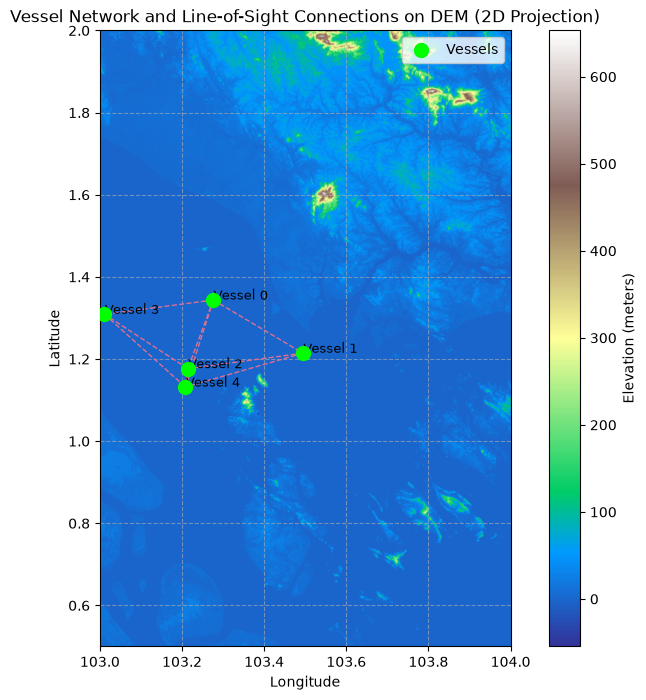

In [18]:
n_ships = 5

#load dem
dem_dataset = load_dem()

#generate initial position
ships_lla = generate_convoy_lla(dem_dataset, n_ships = n_ships)

#set reference point for enu system
lat_ref_deg = ships_lla[0, 0]
lon_ref_deg = ships_lla[0, 1]
alt_ref_m = 0.0

#generate motion paths
individual_speeds_knots, individual_headings_deg = generate_individual_movements(n_ships = n_ships)

#generate los graph
ships_enu = lla_to_enu(ships_lla[:, 0], ships_lla[:, 1], ships_lla[:, 2], lat_ref_deg, lon_ref_deg, alt_ref_m)
ships_enu = ships_enu.T
los_graph = build_los_graph(ships_enu, dem_dataset, lat_ref_deg, lon_ref_deg)

#plot initial positions
plot2D(ships_lla, los_graph, dem_dataset)


# Main Loop

* input ship coords, heading, speed
* generate uav position
* add position to waypoint list

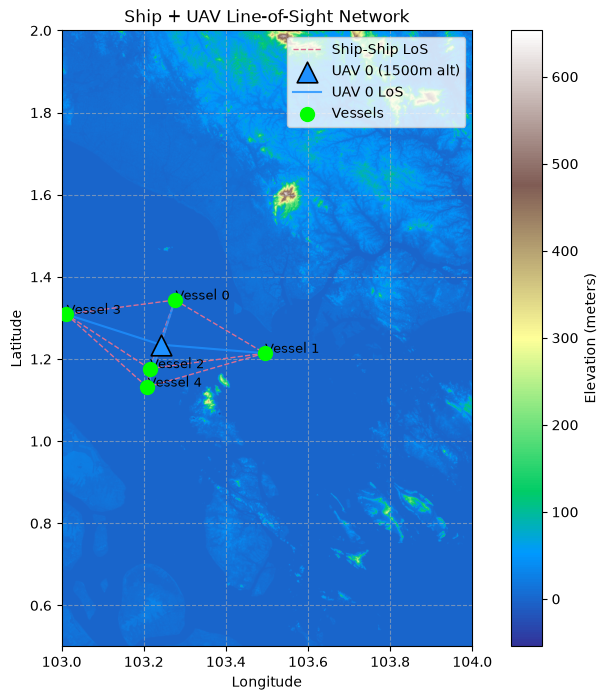

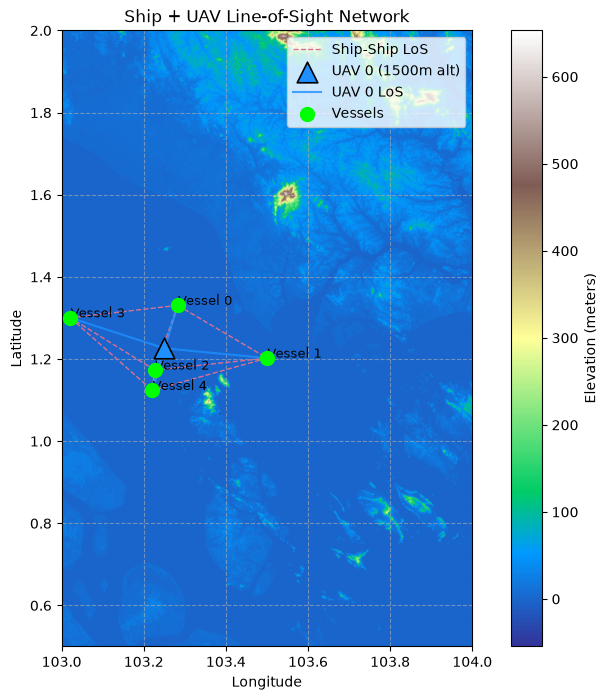

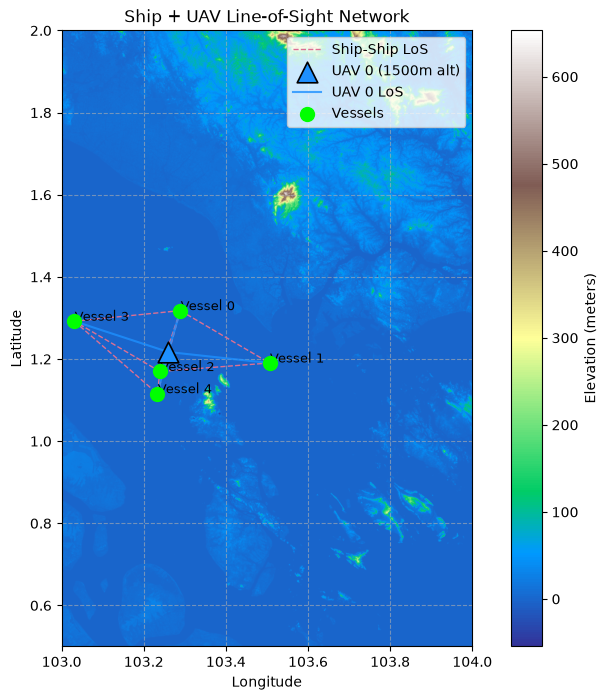

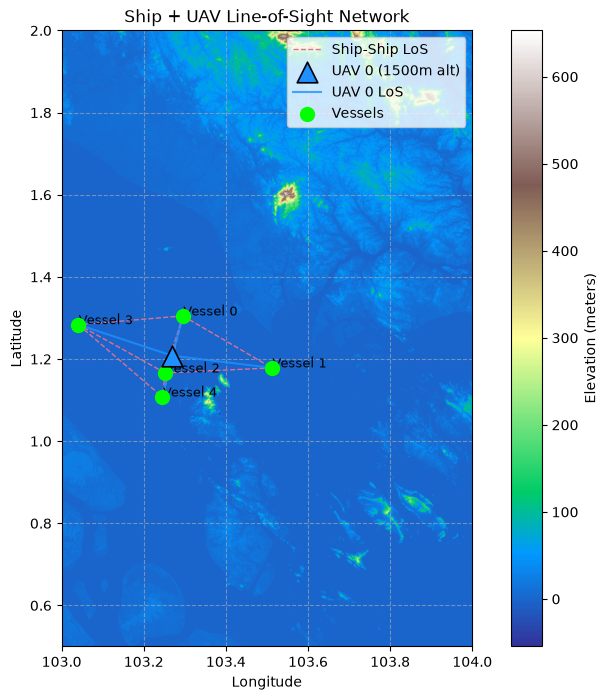

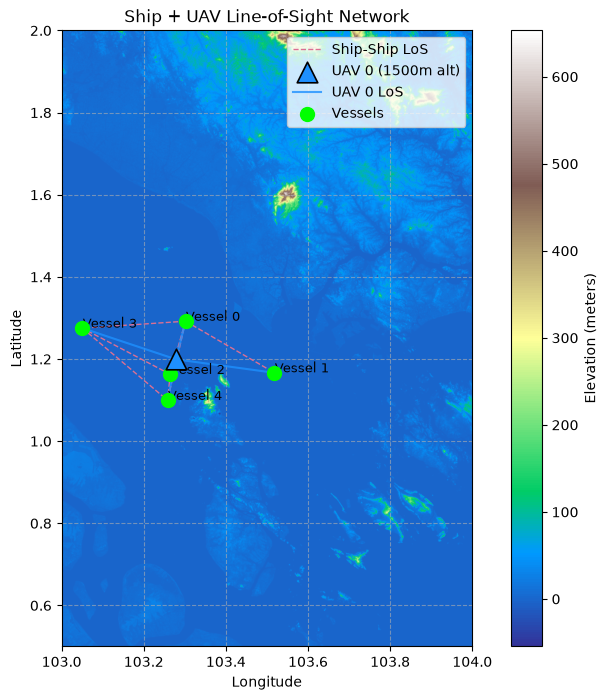

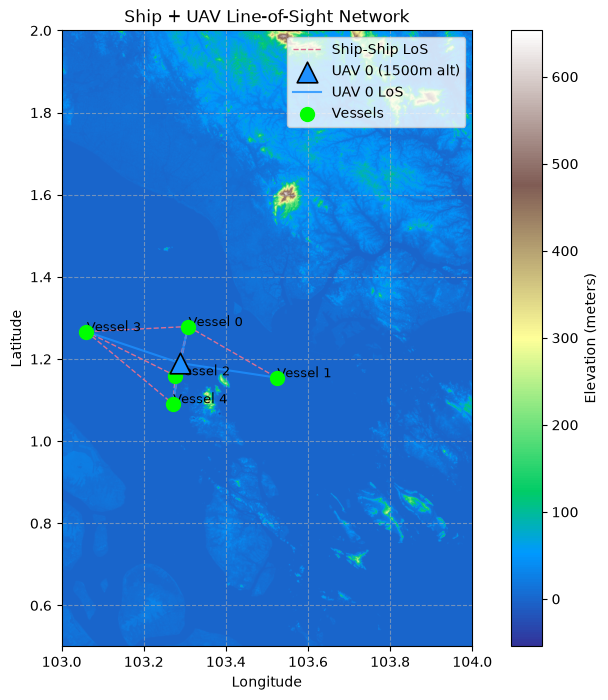

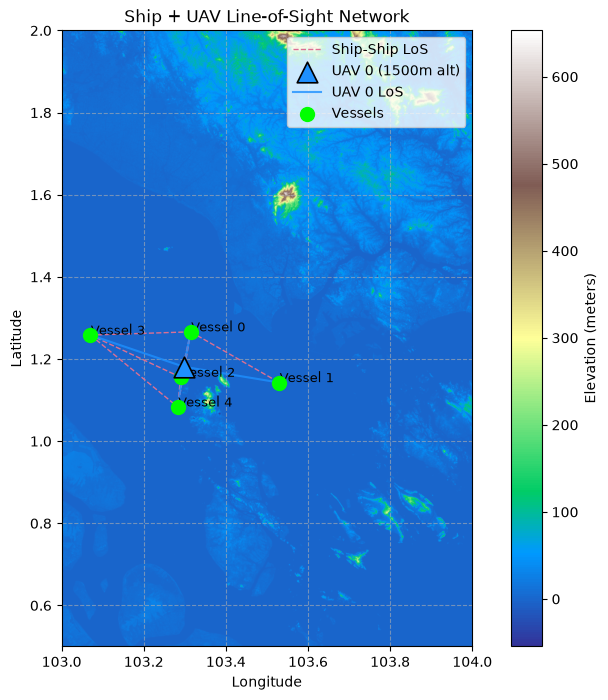

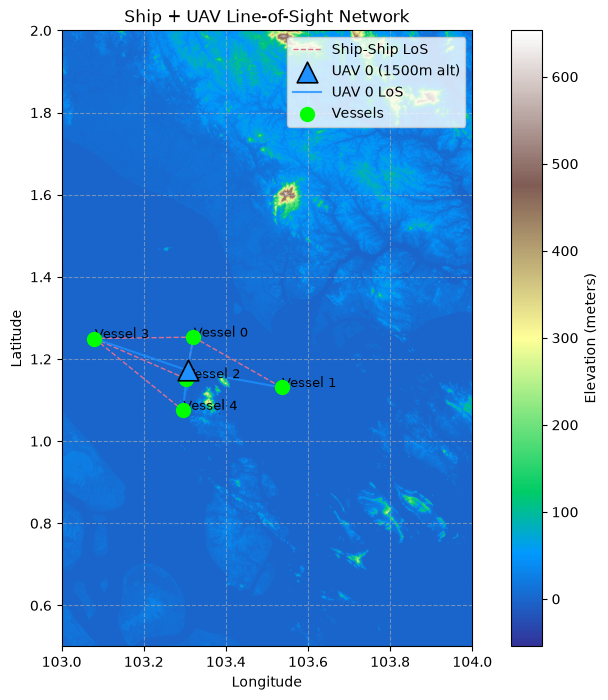

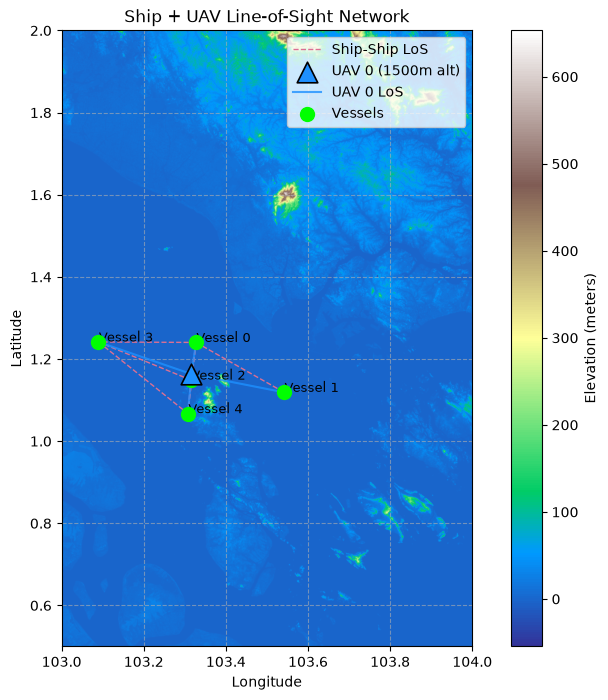

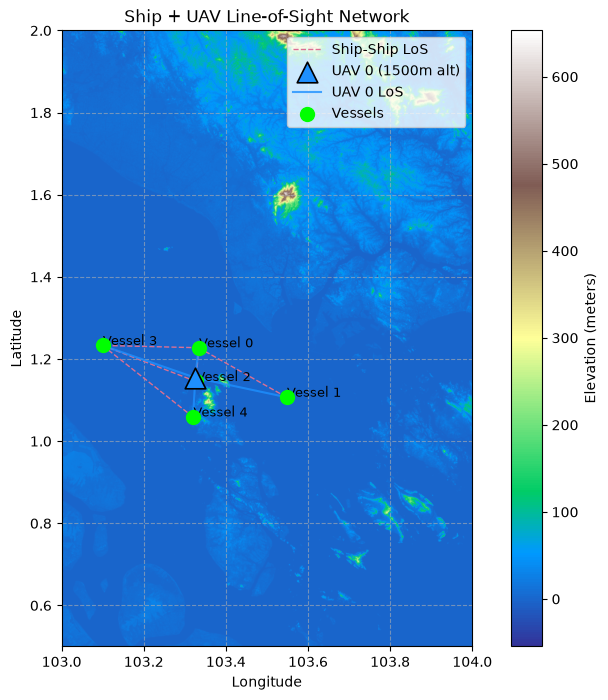

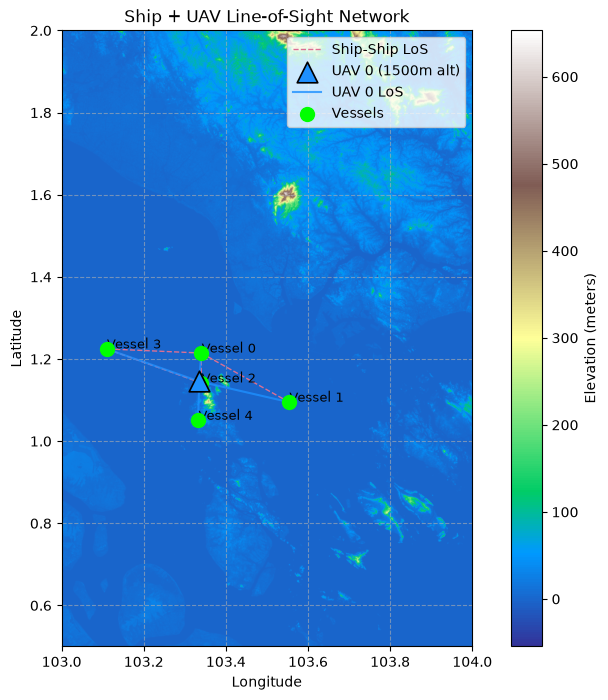

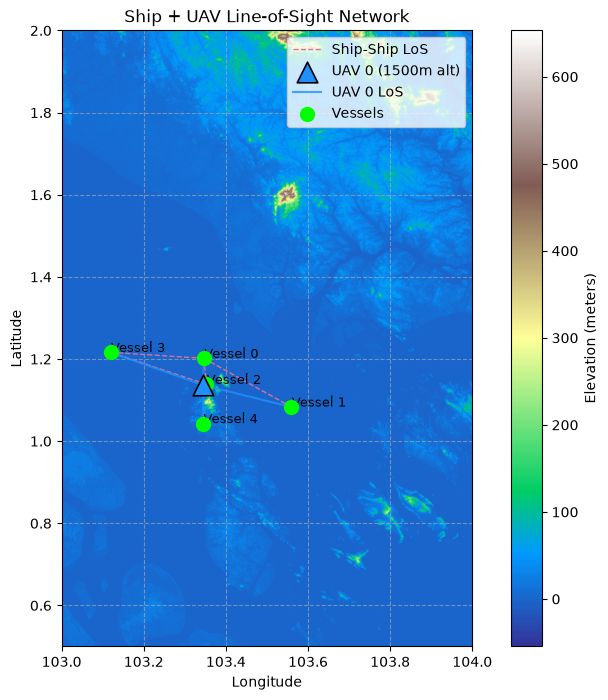

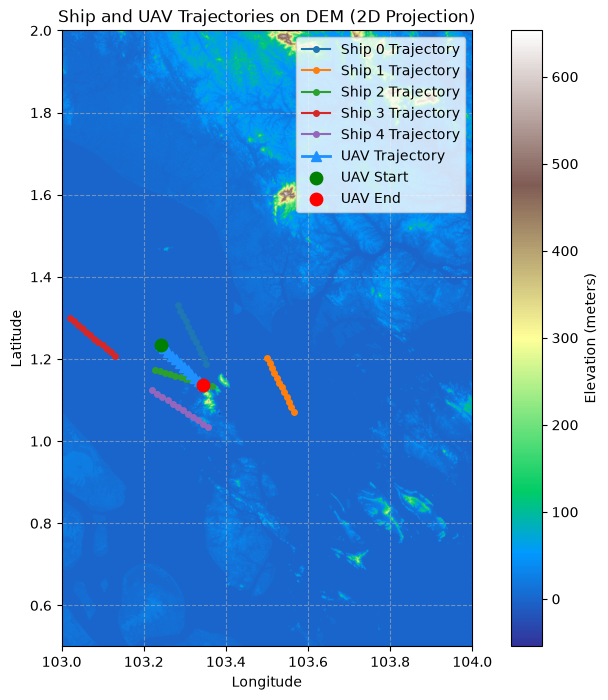

In [19]:
sim_time = 60 #simulation time in minutes
calc_interval = 5 #calculation interval in minutes
main_loop_budget_s = 135.0
placement_budget_s = 10.0

ships_history_lla = []
los_graph_history = []
uav_traj_optns = {} #key = time, value = UAV LLA coordinate
curr_time = 0


while(curr_time < sim_time):
  # place one UAV for the current ship geometry
  ships_enu = lla_to_enu(ships_lla[:, 0], ships_lla[:, 1], ships_lla[:, 2], lat_ref_deg, lon_ref_deg, alt_ref_m).T

  try:
    uav_result = place_uavs(
      ships_enu, dem_dataset, lat_ref_deg, lon_ref_deg,
      time_budget_s=placement_budget_s
    )
  except TimeoutError:
    break
  uav_traj_optns[curr_time] = uav_result['uav_lla'].copy()

  # plot this snapshot: ship-ship LoS + the UAV + its links
  plot2D_with_uav(ships_lla, los_graph, uav_result, dem_dataset)

  # generate new ship lla
  ships_lla = update_ship_positions_lla(ships_lla, individual_speeds_knots, individual_headings_deg, calc_interval)

  # generate new los graph
  ships_enu = lla_to_enu(ships_lla[:, 0], ships_lla[:, 1], ships_lla[:, 2], lat_ref_deg, lon_ref_deg, alt_ref_m).T
  los_graph = build_los_graph(ships_enu, dem_dataset, lat_ref_deg, lon_ref_deg)

  # update history
  ships_history_lla.append(np.copy(ships_lla))
  los_graph_history.append(np.copy(los_graph))

  # move to next time
  curr_time += calc_interval

plot_motion(ships_history_lla, dem_dataset, list(uav_traj_optns.values()))